In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [2]:
# ---------------------------
# Core utilities
# ---------------------------
def _to_pm1(y):
    y = np.asarray(y).astype(float).ravel()
    uniq = set(np.unique(y).tolist())

    if uniq <= {0.0, 1.0}:
        return np.where(y == 0, -1.0, 1.0)

    if uniq <= {-1.0, 1.0}:
        return y

    raise ValueError("Labels must be {0,1} or {-1,+1}.")


def _euclidean_distances(X1, X2):
    X1 = np.asarray(X1, dtype=float)
    X2 = np.asarray(X2, dtype=float)
    X1_sq = np.sum(X1**2, axis=1, keepdims=True)
    X2_sq = np.sum(X2**2, axis=1, keepdims=True).T
    return np.sqrt(np.maximum(X1_sq + X2_sq - 2 * X1 @ X2.T, 0.0))

In [3]:
# ---------------------------
# KNN
# ---------------------------
class KNNClassifier:
    def __init__(self, k=3):
        self.k = k
        self.X = None
        self.y = None

    def fit(self, X, y):
        self.X = np.asarray(X, dtype=float)
        self.y = np.asarray(y)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        dists = _euclidean_distances(X, self.X)
        idx = np.argsort(dists, axis=1)[:, : self.k]
        neighbors = self.y[idx]

        preds = []
        for row in neighbors:
            values, counts = np.unique(row, return_counts=True)
            preds.append(values[np.argmax(counts)])
        return np.array(preds)


class KNNRegressor:
    def __init__(self, k=3):
        self.k = k
        self.X = None
        self.y = None

    def fit(self, X, y):
        self.X = np.asarray(X, dtype=float)
        self.y = np.asarray(y, dtype=float).ravel()
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        dists = _euclidean_distances(X, self.X)
        idx = np.argsort(dists, axis=1)[:, : self.k]
        return np.mean(self.y[idx], axis=1)



In [4]:

# ---------------------------
# KMeans
# ---------------------------
class KMeans:
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=None):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.cluster_centers_ = None
        self.labels_ = None
        self.inertia_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        n_samples, n_features = X.shape

        rng = np.random.default_rng(self.random_state)
        init_idx = rng.choice(n_samples, size=self.n_clusters, replace=False)
        centers = X[init_idx].copy()

        for _ in range(self.max_iter):
            dists = _euclidean_distances(X, centers)
            labels = np.argmin(dists, axis=1)

            new_centers = np.zeros((self.n_clusters, n_features), dtype=float)
            for k in range(self.n_clusters):
                cluster_points = X[labels == k]
                if len(cluster_points) == 0:
                    new_centers[k] = X[rng.integers(0, n_samples)]
                else:
                    new_centers[k] = np.mean(cluster_points, axis=0)

            shift = np.linalg.norm(new_centers - centers)
            centers = new_centers
            if shift < self.tol:
                break

        self.cluster_centers_ = centers
        self.labels_ = labels
        self.inertia_ = np.sum((X - centers[labels]) ** 2)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        dists = _euclidean_distances(X, self.cluster_centers_)
        return np.argmin(dists, axis=1)

    def fit_predict(self, X):
        return self.fit(X).labels_


class ImageKMeansSegmenter:
    def __init__(
        self,
        n_clusters=4,
        max_iter=300,
        tol=1e-4,
        random_state=None,
        resize_max_side=None,
    ):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.resize_max_side = resize_max_side

        self.kmeans = KMeans(
            n_clusters=n_clusters, max_iter=max_iter, tol=tol, random_state=random_state
        )

        self.original_size = None
        self.image_array = None
        self.segmented_array = None
        self.labels_ = None
        self.cluster_centers_ = None

    def load_image(self, image_path):
        img = Image.open(image_path).convert("RGB")

        if self.resize_max_side is not None:
            w, h = img.size
            scale = self.resize_max_side / max(w, h)
            if scale < 1.0:
                new_size = (int(w * scale), int(h * scale))
                img = img.resize(new_size, Image.Resampling.LANCZOS)

        self.original_size = img.size
        self.image_array = np.asarray(img, dtype=np.float32) / 255.0
        return self

    def fit(self):
        if self.image_array is None:
            raise ValueError("Bạn cần load ảnh trước bằng load_image().")

        h, w, c = self.image_array.shape
        pixels = self.image_array.reshape(-1, 3)

        self.kmeans.fit(pixels)
        self.labels_ = self.kmeans.labels_
        self.cluster_centers_ = self.kmeans.cluster_centers_

        segmented_pixels = self.cluster_centers_[self.labels_]
        self.segmented_array = segmented_pixels.reshape(h, w, 3)
        return self

    def segment(self, image_path):
        self.load_image(image_path)
        self.fit()
        return self.get_segmented_image()

    def get_segmented_image(self):
        if self.segmented_array is None:
            raise ValueError("Bạn cần gọi fit() trước.")
        img = np.clip(self.segmented_array * 255.0, 0, 255).astype(np.uint8)
        return Image.fromarray(img)

    def save_segmented(self, out_path):
        segmented_img = self.get_segmented_image()
        segmented_img.save(out_path)

    def show(self, figsize=(12, 5)):
        if self.image_array is None or self.segmented_array is None:
            raise ValueError("Bạn cần load ảnh và fit trước.")

        original_img = np.clip(self.image_array * 255.0, 0, 255).astype(np.uint8)
        segmented_img = np.clip(self.segmented_array * 255.0, 0, 255).astype(np.uint8)

        plt.figure(figsize=figsize)

        plt.subplot(1, 2, 1)
        plt.imshow(original_img)
        plt.title("Original")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(segmented_img)
        plt.title(f"Segmented with k={self.n_clusters}")
        plt.axis("off")

        plt.tight_layout()
        plt.show()


In [5]:

# ---------------------------
# Kernel SVM / SVC
# ---------------------------
class SVM:
    """
    Binary kernel SVM using simplified SMO.
    Labels accepted: {0,1} or {-1,+1}.
    Output predictions: {-1,+1}.
    """

    def __init__(
        self,
        C=1.0,
        kernel="rbf",
        gamma=0.5,
        degree=3,
        coef0=1.0,
        tol=1e-3,
        max_passes=5,
        max_iter=10000,
        random_state=None,
    ):
        self.C = C
        self.kernel = kernel
        self.gamma = gamma
        self.degree = degree
        self.coef0 = coef0
        self.tol = tol
        self.max_passes = max_passes
        self.max_iter = max_iter
        self.random_state = random_state

        self.alphas = None
        self.b = 0.0
        self.X = None
        self.y = None

        self.support_vectors_ = None
        self.support_vector_labels_ = None
        self.support_vector_alphas_ = None

    def _kernel_func(self, X1, X2):
        X1 = np.asarray(X1, dtype=float)
        X2 = np.asarray(X2, dtype=float)

        if self.kernel == "linear":
            return X1 @ X2.T

        if self.kernel == "rbf":
            X1_sq = np.sum(X1**2, axis=1, keepdims=True)
            X2_sq = np.sum(X2**2, axis=1, keepdims=True).T
            sq_dist = X1_sq + X2_sq - 2 * (X1 @ X2.T)
            return np.exp(-self.gamma * sq_dist)

        if self.kernel == "poly":
            return (self.gamma * (X1 @ X2.T) + self.coef0) ** self.degree

        if self.kernel == "sigmoid":
            return np.tanh(self.gamma * (X1 @ X2.T) + self.coef0)

        raise ValueError("kernel must be 'linear', 'rbf', 'poly', or 'sigmoid'.")

    def _decision_row(self, K, i):
        return np.sum(self.alphas * self.y * K[:, i]) + self.b

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = _to_pm1(y)

        m = X.shape[0]
        self.X = X
        self.y = y
        self.alphas = np.zeros(m, dtype=float)
        self.b = 0.0

        K = self._kernel_func(X, X)
        rng = np.random.default_rng(self.random_state)

        passes = 0
        iters = 0

        while passes < self.max_passes and iters < self.max_iter:
            num_changed = 0

            for i in range(m):
                Ei = self._decision_row(K, i) - y[i]

                violates_kkt = (y[i] * Ei < -self.tol and self.alphas[i] < self.C) or (
                    y[i] * Ei > self.tol and self.alphas[i] > 0
                )

                if not violates_kkt:
                    continue

                j = i
                while j == i:
                    j = rng.integers(0, m)

                Ej = self._decision_row(K, j) - y[j]

                alpha_i_old = self.alphas[i]
                alpha_j_old = self.alphas[j]

                if y[i] != y[j]:
                    L = max(0.0, alpha_j_old - alpha_i_old)
                    H = min(self.C, self.C + alpha_j_old - alpha_i_old)
                else:
                    L = max(0.0, alpha_i_old + alpha_j_old - self.C)
                    H = min(self.C, alpha_i_old + alpha_j_old)

                if L == H:
                    continue

                # eta is negative for PSD kernels in this formulation
                eta = 2.0 * K[i, j] - K[i, i] - K[j, j]
                if eta >= 0:
                    continue

                self.alphas[j] = alpha_j_old - (y[j] * (Ei - Ej)) / eta
                self.alphas[j] = np.clip(self.alphas[j], L, H)

                if abs(self.alphas[j] - alpha_j_old) < 1e-6:
                    self.alphas[j] = alpha_j_old
                    continue

                self.alphas[i] = alpha_i_old + y[i] * y[j] * (
                    alpha_j_old - self.alphas[j]
                )

                b1 = (
                    self.b
                    - Ei
                    - y[i] * (self.alphas[i] - alpha_i_old) * K[i, i]
                    - y[j] * (self.alphas[j] - alpha_j_old) * K[i, j]
                )
                b2 = (
                    self.b
                    - Ej
                    - y[i] * (self.alphas[i] - alpha_i_old) * K[i, j]
                    - y[j] * (self.alphas[j] - alpha_j_old) * K[j, j]
                )

                if 0 < self.alphas[i] < self.C:
                    self.b = b1
                elif 0 < self.alphas[j] < self.C:
                    self.b = b2
                else:
                    self.b = 0.5 * (b1 + b2)

                num_changed += 1

            if num_changed == 0:
                passes += 1
            else:
                passes = 0

            iters += 1

        sv = self.alphas > 1e-8
        self.support_vectors_ = self.X[sv]
        self.support_vector_labels_ = self.y[sv]
        self.support_vector_alphas_ = self.alphas[sv]
        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(1, -1)

        if self.support_vectors_ is None or len(self.support_vectors_) == 0:
            return np.zeros(X.shape[0], dtype=float) + self.b

        K = self._kernel_func(self.support_vectors_, X)
        scores = (
            self.support_vector_alphas_ * self.support_vector_labels_
        ) @ K + self.b
        return scores

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)


class SVC(SVM):
    pass


In [6]:
# ---------------------------
# Visualization helpers
# ---------------------------
def _plot_3d_scatter(
    X, labels, title, centers=None, query_points=None, query_labels=None
):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    X = np.asarray(X)
    labels = np.asarray(labels)

    unique = np.unique(labels)
    for lab in unique:
        pts = X[labels == lab]
        ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=28, label=f"label {lab}")

    if centers is not None:
        centers = np.asarray(centers)
        ax.scatter(
            centers[:, 0],
            centers[:, 1],
            centers[:, 2],
            s=180,
            marker="X",
            label="centers",
        )

    if query_points is not None:
        query_points = np.asarray(query_points)
        if query_labels is None:
            ax.scatter(
                query_points[:, 0],
                query_points[:, 1],
                query_points[:, 2],
                s=140,
                marker="*",
                label="queries",
            )
        else:
            query_labels = np.asarray(query_labels)
            for lab in np.unique(query_labels):
                pts = query_points[query_labels == lab]
                ax.scatter(
                    pts[:, 0],
                    pts[:, 1],
                    pts[:, 2],
                    s=140,
                    marker="*",
                    label=f"query pred {lab}",
                )

    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("x3")
    ax.legend()
    fig.tight_layout()
    fig.show()

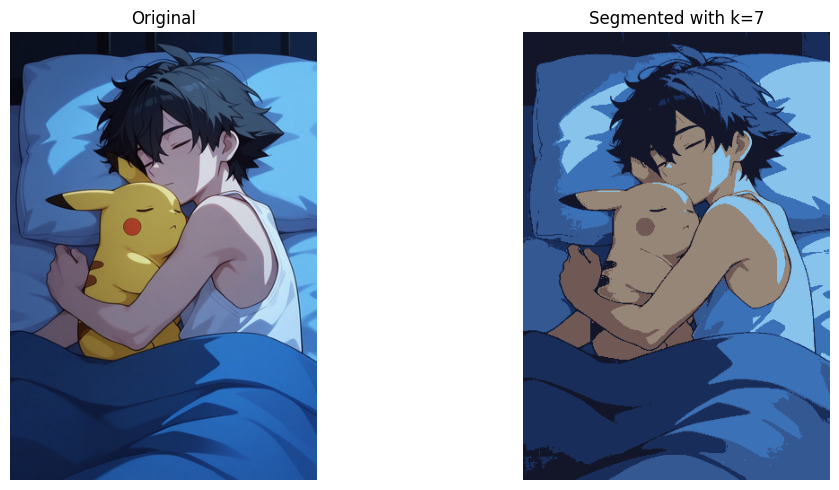

In [7]:
out_dir = Path("outputs")
out_dir.mkdir(parents=True, exist_ok=True)

image_path = "images/1.jpeg"
k = 7

segmenter = ImageKMeansSegmenter(
    n_clusters=k, max_iter=200, tol=1e-4, resize_max_side=500
)

segmenter.load_image(image_path).fit()
segmenter.show()

/tmp/ipykernel_95653/3300290830.py:59: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


KMeans cluster centers:
 [[-0.22828797 -0.33466975 -0.49974848]
 [ 0.35779327  0.32336311  0.51543658]
 [ 2.51291128  5.09924565  2.95827251]]
KNN query predictions: [0 1 1 1]
SVM-linear training accuracy: 1.0
SVM-rbf training accuracy: 1.0
SVC-poly training accuracy: 1.0


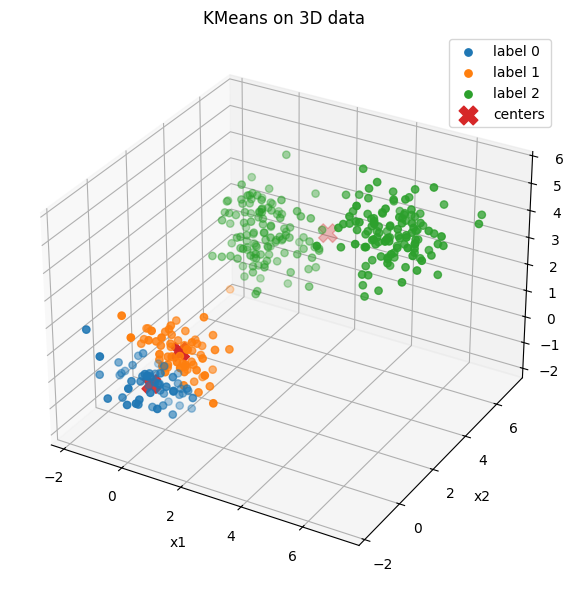

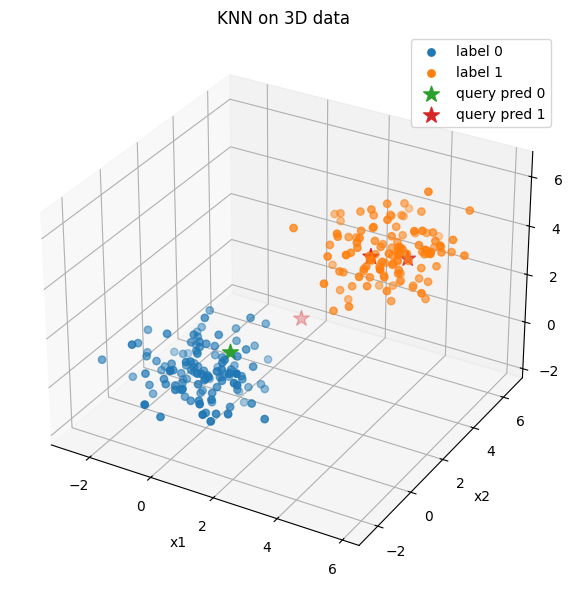

In [8]:

def make_blobs_3d(n_samples=300, centers=None, cluster_std=0.8, random_state=42):
    rng = np.random.default_rng(random_state)
    if centers is None:
        centers = np.array(
            [
                [0.0, 0.0, 0.0],
                [4.0, 4.0, 4.0],
                [0.0, 5.0, 2.0],
            ],
            dtype=float,
        )

    centers = np.asarray(centers, dtype=float)
    k = len(centers)
    per_cluster = n_samples // k
    remainder = n_samples % k

    Xs = []
    ys = []
    for i, c in enumerate(centers):
        n_i = per_cluster + (1 if i < remainder else 0)
        Xs.append(rng.normal(loc=c, scale=cluster_std, size=(n_i, centers.shape[1])))
        ys.append(np.full(n_i, i, dtype=int))

    X = np.vstack(Xs)
    y = np.concatenate(ys)

    perm = rng.permutation(n_samples)
    return X[perm], y[perm]


def make_binary_data_3d(n_samples=240, class_sep=3.5, random_state=7):
    rng = np.random.default_rng(random_state)
    n0 = n_samples // 2
    n1 = n_samples - n0

    c0 = np.array([0.0, 0.0, 0.0], dtype=float)
    c1 = np.array([class_sep, class_sep, class_sep], dtype=float)

    X0 = rng.normal(loc=c0, scale=0.9, size=(n0, 3))
    X1 = rng.normal(loc=c1, scale=0.9, size=(n1, 3))

    X = np.vstack([X0, X1])
    y = np.array([0] * n0 + [1] * n1)

    perm = rng.permutation(n_samples)
    return X[perm], y[perm]


# 1) KMeans demo on 3D data
X_cluster, _ = make_blobs_3d(
    n_samples=360,
    centers=np.array(
        [
            [0.0, 0.0, 0.0],
            [5.0, 4.5, 4.0],
            [0.0, 5.5, 2.0],
        ]
    ),
    cluster_std=0.75,
    random_state=12,
)

km = KMeans(n_clusters=3, random_state=12).fit(X_cluster)
_plot_3d_scatter(
    X_cluster,
    km.labels_,
    "KMeans on 3D data",
    centers=km.cluster_centers_,
)

# 2) KNN demo on 3D data
X_knn, y_knn = make_binary_data_3d(n_samples=240, class_sep=3.8, random_state=21)
knn = KNNClassifier(k=5).fit(X_knn, y_knn)

query_points = np.array(
    [
        [0.4, 0.7, 0.5],
        [3.5, 3.3, 4.0],
        [2.0, 2.0, 1.7],
        [4.3, 4.0, 3.8],
    ]
)
query_preds = knn.predict(query_points)

_plot_3d_scatter(
    X_knn,
    y_knn,
    "KNN on 3D data",
    query_points=query_points,
    query_labels=query_preds,
)

# 3) SVM / SVC demos on 3D binary data
y_pm1 = _to_pm1(y_knn)

svm_linear = SVM(
    C=1.0, kernel="linear", random_state=21, max_passes=8, max_iter=2000
).fit(X_knn, y_pm1)
svm_rbf = SVM(
    C=1.0, kernel="rbf", gamma=0.25, random_state=21, max_passes=8, max_iter=2000
).fit(X_knn, y_pm1)
svc_poly = SVC(
    C=1.0,
    kernel="poly",
    gamma=0.5,
    degree=3,
    coef0=1.0,
    random_state=21,
    max_passes=8,
    max_iter=2000,
).fit(X_knn, y_pm1)

print("KMeans cluster centers:\n", km.cluster_centers_)
print("KNN query predictions:", query_preds)
print("SVM-linear training accuracy:", np.mean(svm_linear.predict(X_knn) == y_pm1))
print("SVM-rbf training accuracy:", np.mean(svm_rbf.predict(X_knn) == y_pm1))
print("SVC-poly training accuracy:", np.mean(svc_poly.predict(X_knn) == y_pm1))